In [ ]:
import os, sys, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, brier_score_loss
)

warnings.filterwarnings("ignore")

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

LABEL_HORIZON = pd.Timedelta(days=7)

ZIP_PATH = "archive_3.zip"

In [ ]:
from google.colab import files

if not os.path.exists(ZIP_PATH):
    uploaded = files.upload()
    ZIP_PATH = next(iter(uploaded))

with zipfile.ZipFile(ZIP_PATH) as zf:

    print("Files in ZIP:")
    for info in zf.infolist():
        print(f"  {info.filename:25s} {info.file_size/1e6:8.1f} MB")

    csv_name = [
        n for n in zf.namelist()
        if n.lower().endswith(".csv")
    ][0]

    dtypes = {
        "event_type": "category",
        "product_id": "int64",
        "category_id": "int64",
        "category_code": "category",
        "brand": "category",
        "price": "float32",
        "user_id": "int64",
        "user_session": "object"
    }

    with zf.open(csv_name) as f:
        raw = pd.read_csv(f, dtype=dtypes)

print("\nShape:", raw.shape)

print("\nColumns / dtypes:\n", raw.dtypes)

print("\nMissing values:\n", raw.isna().sum())

print("\nEvent types:\n", raw["event_type"].value_counts())

print(
    "\nUsers:", raw["user_id"].nunique(),
    "| Products:", raw["product_id"].nunique(),
    "| Sessions:", raw["user_session"].nunique()
)

print(
    "Category ids:", raw["category_id"].nunique(),
    "| Category codes:", raw["category_code"].nunique(),
    "| Brands:", raw["brand"].nunique()
)

print(
    "Time range:",
    raw["event_time"].min(),
    "->",
    raw["event_time"].max()
)

print(
    f"Memory: {raw.memory_usage(deep=True).sum()/1e6:.0f} MB"
)

display(raw.sample(8, random_state=RANDOM_STATE))

Saving archive (3).zip to archive (3).zip
Files in ZIP:
  events.csv                   105.8 MB

Shape: (885129, 9)

Columns / dtypes:
 event_time         object
event_type       category
product_id          int64
category_id         int64
category_code    category
brand            category
price             float32
user_id             int64
user_session       object
dtype: object

Missing values:
 event_time            0
event_type            0
product_id            0
category_id           0
category_code    236219
brand            212364
price                 0
user_id               0
user_session        165
dtype: int64

Event types:
 event_type
view        793748
cart         54035
purchase     37346
Name: count, dtype: int64

Users: 407283 | Products: 53453 | Sessions: 490398
Category ids: 718 | Category codes: 107 | Brands: 999
Time range: 2020-09-24 11:57:06 UTC -> 2021-02-28 23:59:09 UTC
Memory: 145 MB


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
192708,2020-11-01 14:36:11 UTC,view,4156279,2144415922587172973,electronics.telephone,NaN,12.220000,1515915625533221908,krDzDYA6J0
43645,2020-10-04 13:48:49 UTC,view,1283611,2144415952391898012,appliances.environment.vacuum,bort,170.000000,1515915625469806973,C8YU0DjTP8
148601,2020-10-25 06:27:19 UTC,view,3791351,2144415926966026460,computers.components.cpu,amd,204.289993,1515915625530210252,GFm0pEaVjK
592601,2021-01-12 08:26:56 UTC,view,3957221,2144415922427789416,computers.components.videocards,asus,451.320007,1515915625592186998,E57Elq8HVE
355859,2020-11-26 12:29:34 UTC,view,227145,2144415921085612102,NaN,NaN,13.000000,1515915625544205939,jvqzdCSUUw
92251,2020-10-15 11:12:31 UTC,view,606348,2144415925011480748,stationery.cartrige,netproduct,13.570000,1515915625526325182,ZFVufBPJdu
301609,2020-11-17 17:49:12 UTC,purchase,564740,2144415935673401802,NaN,NaN,11.560000,1515915625540490356,MpVLUpcIUV
307606,2020-11-18 13:24:19 UTC,view,1745516,2144415924021624977,electronics.tablet,baseus,35.869999,1515915625540835817,yw3b6lL9Yj


In [ ]:
df = raw.copy()

n0 = len(df)

df["event_time"] = pd.to_datetime(
    df["event_time"].str.replace(" UTC", "", regex=False),
    errors="coerce"
)

checks = {
    "unparseable timestamps": df["event_time"].isna(),
    "unknown event type": ~df["event_type"].isin(
        ["view", "cart", "purchase"]
    ),
    "non-positive / missing price": ~(df["price"] > 0),
    "missing user_session": df["user_session"].isna(),
}

for name, mask in checks.items():
    print(f"{name:32s}: {mask.sum():,}")

df = df[
    ~np.logical_or.reduce(list(checks.values()))
].copy()

n_dup = df.duplicated().sum()

df = df.drop_duplicates()

print(
    f"exact duplicate rows removed    : {n_dup:,}"
)

print(
    "No cancellation/return events exist "
    "in this dataset."
)

df["category_code"] = (
    df["category_code"]
    .cat.add_categories("unknown")
    .fillna("unknown")
)

df["brand"] = (
    df["brand"]
    .cat.add_categories("unknown")
    .fillna("unknown")
)

df["top_category"] = (
    df["category_code"]
    .astype(str)
    .str.split(".")
    .str[0]
)

print(
    "max distinct prices per product:",
    df.groupby("product_id")["price"].nunique().max(),
    "| max categories per product:",
    df.groupby("product_id")["category_id"].nunique().max()
)

df = df.sort_values(
    "event_time",
    kind="stable"
).reset_index(drop=True)

for e in ["view", "cart", "purchase"]:
    df[f"is_{e}"] = (
        df["event_type"] == e
    ).astype("int8")

print(
    f"\nRows kept: {len(df):,} of {n0:,}"
)

unparseable timestamps          : 0
unknown event type              : 0
non-positive / missing price    : 0
missing user_session            : 165
exact duplicate rows removed    : 652
No cancellation/return events exist in this dataset.
max distinct prices per product: 1 | max categories per product: 1

Rows kept: 884,312 of 885,129


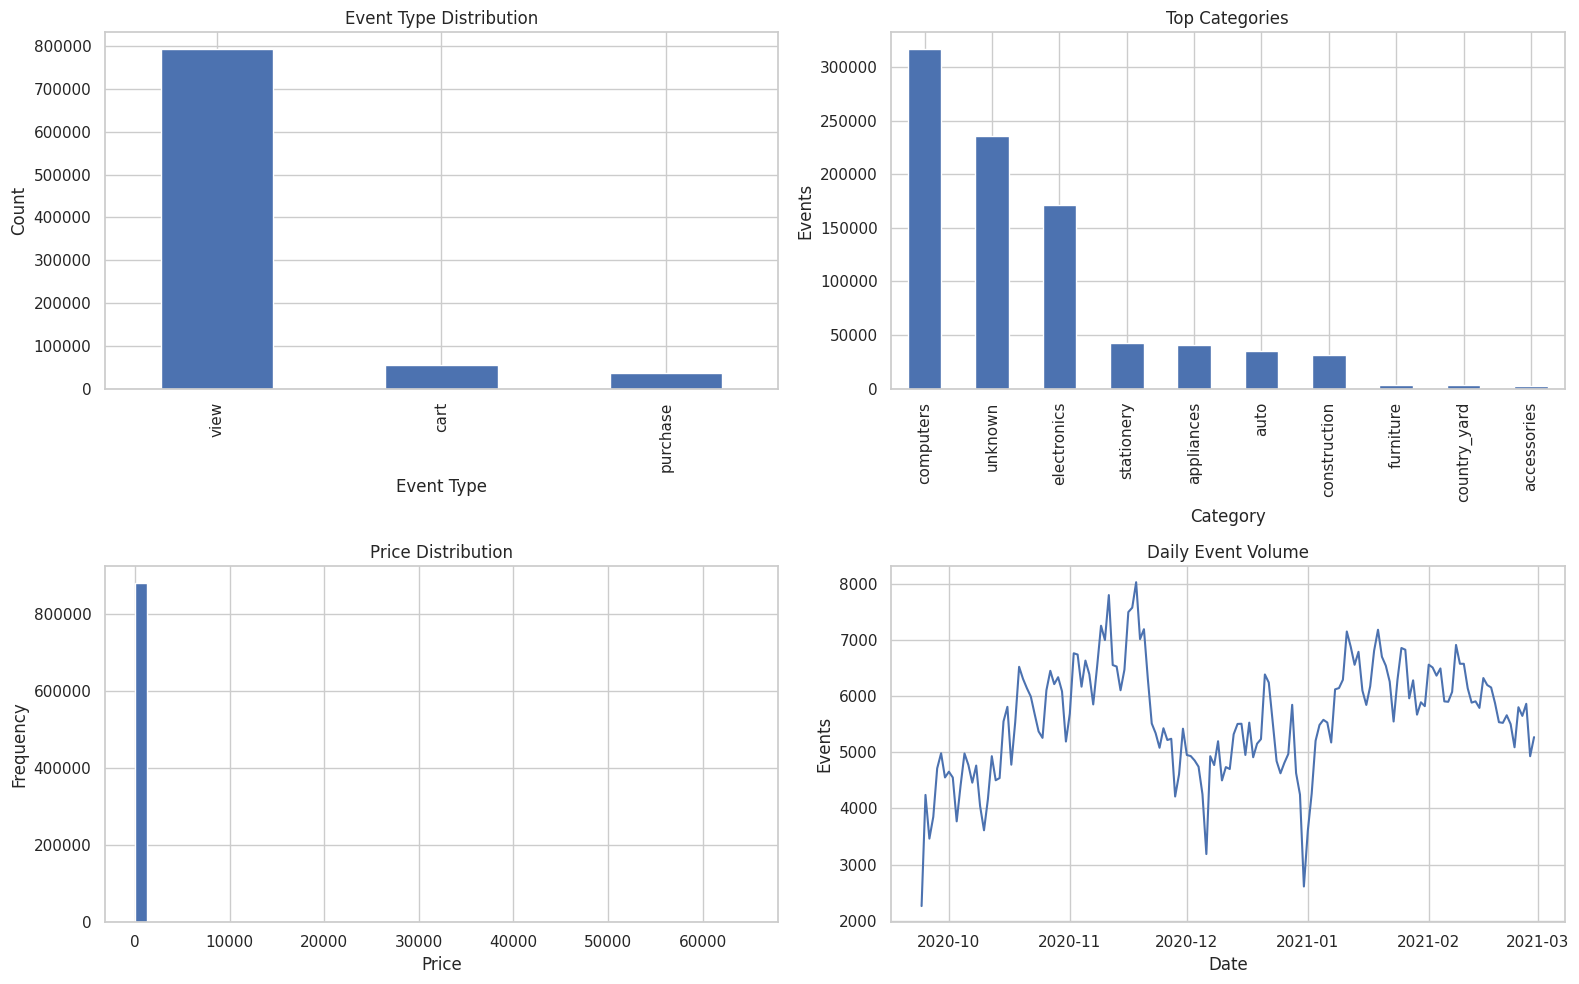

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Event counts
df["event_type"].value_counts().plot(
    kind="bar",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Event Type Distribution")
axes[0, 0].set_xlabel("Event Type")
axes[0, 0].set_ylabel("Count")

# Top categories
(
    df["top_category"]
    .value_counts()
    .head(10)
    .plot(
        kind="bar",
        ax=axes[0, 1]
    )
)

axes[0, 1].set_title("Top Categories")
axes[0, 1].set_xlabel("Category")
axes[0, 1].set_ylabel("Events")

# Price distribution
axes[1, 0].hist(
    df["price"],
    bins=50
)

axes[1, 0].set_title("Price Distribution")
axes[1, 0].set_xlabel("Price")
axes[1, 0].set_ylabel("Frequency")

# Daily events
daily = (
    df.set_index("event_time")
    .resample("D")
    .size()
)

axes[1, 1].plot(daily.index, daily.values)

axes[1, 1].set_title("Daily Event Volume")
axes[1, 1].set_xlabel("Date")
axes[1, 1].set_ylabel("Events")

plt.tight_layout()
plt.show()

In [ ]:
# Cell 5 — Define prediction target (leak-free)

# One sample per (user, session, product): the first view of that product in that user's session.
# (user_id is part of the key because some user_session ids are shared by several user_ids in this data.)

view_rows = df[df["is_view"].eq(1)]

sample_idx = view_rows.drop_duplicates(
    ["user_id", "user_session", "product_id"],
    keep="first"
).index

samples = df.loc[
    sample_idx,
    ["event_time", "user_id", "product_id", "category_id", "user_session"]
].copy()

samples["row"] = sample_idx

# Next purchase of the same (user, product) located strictly AFTER
# the prediction row in the time-sorted log

purch = df.loc[
    df["is_purchase"].eq(1),
    ["event_time", "user_id", "product_id"]
].rename(columns={"event_time": "purchase_time"})

purch["purchase_row"] = purch.index

samples = pd.merge_asof(
    samples,
    purch,
    left_on="row",
    right_on="purchase_row",
    by=["user_id", "product_id"],
    direction="forward",
    allow_exact_matches=False
)

in_window = (
    samples["purchase_time"] - samples["event_time"]
) <= LABEL_HORIZON

samples["target"] = in_window.astype("int8")

samples["label_row"] = samples["purchase_row"].where(
    in_window
)  # future purchase that makes label 1

samples = samples.drop(
    columns=["purchase_time", "purchase_row"]
).set_index("row")

print(
    f"Samples: {len(samples):,} | "
    f"positive rate: {samples['target'].mean():.2%}"
)

Samples: 631,353 | positive rate: 5.01%


In [ ]:
# Cell 6 — Feature engineering
# Every feature at row i uses only rows < i (df is time-sorted):
# cumulative sums minus the current row.

def prior_cumsum(frame, keys, col):
    return frame.groupby(keys, sort=False)[col].cumsum() - frame[col]


f = df[
    [
        "event_time",
        "user_id",
        "product_id",
        "category_id",
        "category_code",
        "brand",
        "price",
        "top_category",
        "user_session",
        "is_view",
        "is_cart",
        "is_purchase"
    ]
].copy()


f["price_view"] = f["price"] * f["is_view"]

f["new_session"] = (
    ~f.duplicated(["user_id", "user_session"])
).astype("int8")


# ---------------------------------------------------------
# Product, category, brand and user history
# ---------------------------------------------------------

for key, pre in [
    ("product_id", "p"),
    ("category_id", "c"),
    ("brand", "b"),
    ("user_id", "u")
]:
    for e in ["view", "cart", "purchase"]:
        f[f"{pre}_{e}s"] = prior_cumsum(
            f,
            key,
            f"is_{e}"
        )


# ---------------------------------------------------------
# Price history
# ---------------------------------------------------------

f["c_price_sum"] = prior_cumsum(
    f,
    "category_id",
    "price_view"
)

f["u_price_sum"] = prior_cumsum(
    f,
    "user_id",
    "price_view"
)


# ---------------------------------------------------------
# User session history
# ---------------------------------------------------------

f["u_sessions"] = prior_cumsum(
    f,
    "user_id",
    "new_session"
)


# ---------------------------------------------------------
# User-category and user-product history
# ---------------------------------------------------------

for e in ["view", "cart", "purchase"]:

    f[f"uc_{e}s"] = prior_cumsum(
        f,
        ["user_id", "category_id"],
        f"is_{e}"
    )

    f[f"up_{e}s"] = prior_cumsum(
        f,
        ["user_id", "product_id"],
        f"is_{e}"
    )


# ---------------------------------------------------------
# User-level helper features
# ---------------------------------------------------------

f["u_events"] = (
    f["u_views"]
    + f["u_carts"]
    + f["u_purchases"]
)

f["u_first_time"] = (
    f.groupby("user_id")["event_time"]
    .transform("first")
)

f["u_last_time"] = (
    f.groupby("user_id")["event_time"]
    .shift(1)
)


# ---------------------------------------------------------
# Category encoding
# ---------------------------------------------------------

TOP_CATS = sorted(
    df["top_category"].unique()
)

TOP_CAT_CODE = {
    c: i
    for i, c in enumerate(TOP_CATS)
}


# ---------------------------------------------------------
# Convert raw history into model features
# ---------------------------------------------------------

def finalize_features(x, t):

    """
    Turn raw prior counts into model features.
    Shared by training and the recommender.
    """

    out = pd.DataFrame(index=x.index)


    # Product price
    out["log_price"] = np.log1p(
        x["price"].astype(float)
    )


    # Top-level category
    out["top_category"] = (
        x["top_category"]
        .map(TOP_CAT_CODE)
        .astype(float)
    )


    # Whether a brand is available
    out["has_brand"] = (
        x["brand"].astype(str) != "unknown"
    ).astype(int)


    # -----------------------------------------------------
    # Product / category / brand statistics
    # -----------------------------------------------------

    for pre in ["p", "c", "b"]:

        out[f"{pre}_views"] = (
            x[f"{pre}_views"]
        )

        out[f"{pre}_carts"] = (
            x[f"{pre}_carts"]
        )

        out[f"{pre}_purchases"] = (
            x[f"{pre}_purchases"]
        )

        # Smoothed purchase conversion rate
        out[f"{pre}_purchase_rate"] = (
            x[f"{pre}_purchases"] + 0.4
        ) / (
            x[f"{pre}_views"] + 20
        )

        # Smoothed cart conversion rate
        out[f"{pre}_cart_rate"] = (
            x[f"{pre}_carts"] + 0.6
        ) / (
            x[f"{pre}_views"] + 20
        )


    # -----------------------------------------------------
    # Price compared with category average
    # -----------------------------------------------------

    cat_mean_price = (
        x["c_price_sum"]
        /
        x["c_views"].replace(0, np.nan)
    )

    out["price_vs_category"] = (
        x["price"]
        /
        cat_mean_price
    )


    # -----------------------------------------------------
    # User history
    # -----------------------------------------------------

    out["u_views"] = x["u_views"]

    out["u_carts"] = x["u_carts"]

    out["u_purchases"] = x["u_purchases"]

    out["u_sessions"] = x["u_sessions"]


    # -----------------------------------------------------
    # User recency
    # -----------------------------------------------------

    has_hist = x["u_events"] > 0

    out["u_days_since_first"] = np.where(
        has_hist,
        (
            t - x["u_first_time"]
        ).dt.total_seconds() / 86400,
        np.nan
    )

    out["u_hours_since_last"] = np.where(
        has_hist,
        (
            t - x["u_last_time"]
        ).dt.total_seconds() / 3600,
        np.nan
    )


    # -----------------------------------------------------
    # Price compared with user's average viewed price
    # -----------------------------------------------------

    u_mean_price = (
        x["u_price_sum"]
        /
        x["u_views"].replace(0, np.nan)
    )

    out["price_vs_user_mean"] = (
        x["price"]
        /
        u_mean_price
    )


    # -----------------------------------------------------
    # User-category and user-product interaction history
    # -----------------------------------------------------

    for e in ["views", "carts", "purchases"]:

        # IMPORTANT:
        # These are uc_views, up_views, uc_carts,
        # up_carts, etc. — NOT uc_viewss.

        out[f"uc_{e}"] = (
            x[f"uc_{e}"]
        )

        out[f"up_{e}"] = (
            x[f"up_{e}"]
        )


    # -----------------------------------------------------
    # Share of user's views belonging to this category
    # -----------------------------------------------------

    out["uc_view_share"] = (
        x["uc_views"]
        /
        x["u_views"].replace(0, np.nan)
    )


    return out


# ---------------------------------------------------------
# Build final feature matrix
# ---------------------------------------------------------

X_all = finalize_features(
    f.loc[samples.index],
    f.loc[
        samples.index,
        "event_time"
    ]
)


FEATURES = list(
    X_all.columns
)


# Categorical feature mask for HistGradientBoosting
CAT_MASK = [
    c == "top_category"
    for c in FEATURES
]


# Target
y_all = samples["target"]


# Prediction timestamps
t_all = samples["event_time"]


# ---------------------------------------------------------
# Show result
# ---------------------------------------------------------

print(
    f"{len(FEATURES)} features:",
    FEATURES
)

display(
    X_all.describe()
    .T[
        [
            "mean",
            "min",
            "max"
        ]
    ]
    .round(3)
)

33 features: ['log_price', 'top_category', 'has_brand', 'p_views', 'p_carts', 'p_purchases', 'p_purchase_rate', 'p_cart_rate', 'c_views', 'c_carts', 'c_purchases', 'c_purchase_rate', 'c_cart_rate', 'b_views', 'b_carts', 'b_purchases', 'b_purchase_rate', 'b_cart_rate', 'price_vs_category', 'u_views', 'u_carts', 'u_purchases', 'u_sessions', 'u_days_since_first', 'u_hours_since_last', 'price_vs_user_mean', 'uc_views', 'up_views', 'uc_carts', 'up_carts', 'uc_purchases', 'up_purchases', 'uc_view_share']


,mean,min,max
log_price,4.224,0.199,11.079
top_category,7.785,0.000,14.000
has_brand,0.755,0.000,1.000
p_views,304.429,0.000,12791.000
p_carts,31.764,0.000,1220.000
p_purchases,18.779,0.000,564.000
p_purchase_rate,0.037,0.000,0.696
p_cart_rate,0.055,0.001,0.433
c_views,9659.003,0.000,97034.000
c_carts,995.202,0.000,12683.000


In [ ]:
# Cell 7 — Time-based train / validation / test split

# Gaps of >= 7 days so no label window overlaps the next period.

split = pd.Series(
    "drop",
    index=samples.index
)

split[
    t_all < "2020-12-25"
] = "train"

split[
    (t_all >= "2021-01-01")
    & (t_all < "2021-01-22")
] = "valid"

split[
    (t_all >= "2021-02-01")
    & (t_all < "2021-02-22")
] = "test"


parts = {
    s: (
        X_all[split == s],
        y_all[split == s]
    )
    for s in ["train", "valid", "test"]
}


for s, (X, y) in parts.items():

    print(
        f"{s:5s}: "
        f"{len(X):>7,} samples | "
        f"{t_all[split == s].min():%Y-%m-%d} -> "
        f"{t_all[split == s].max():%Y-%m-%d} | "
        f"positive rate {y.mean():.2%}"
    )


(X_tr, y_tr), (X_va, y_va), (X_te, y_te) = (
    parts["train"],
    parts["valid"],
    parts["test"]
)

train: 361,941 samples | 2020-09-24 -> 2020-12-24 | positive rate 4.65%
valid:  87,691 samples | 2021-01-01 -> 2021-01-21 | positive rate 5.38%
test :  90,212 samples | 2021-02-01 -> 2021-02-21 | positive rate 5.55%


In [ ]:
# Cell 8 — Train ML models

# Class imbalance:
# balanced class weights during training
# + decision threshold tuned on validation.

log_cols = [
    i
    for i, c in enumerate(FEATURES)
    if not c.startswith(
        ("price_vs", "has_", "top_", "log_")
    )
    and "rate" not in c
    and "share" not in c
]


# ---------------------------------------------------------
# Logistic Regression
# ---------------------------------------------------------

logreg = make_pipeline(
    SimpleImputer(strategy="median"),

    FunctionTransformer(
        lambda a: np.where(
            np.isin(
                np.arange(a.shape[1]),
                log_cols
            ),
            np.log1p(
                np.clip(a, 0, None)
            ),
            a
        )
    ),

    StandardScaler(),

    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    )
)

logreg.fit(X_tr, y_tr)


# ---------------------------------------------------------
# HistGradientBoosting
# ---------------------------------------------------------

hgb = HistGradientBoostingClassifier(
    learning_rate=0.06,
    max_iter=400,
    max_leaf_nodes=48,
    min_samples_leaf=100,
    l2_regularization=1.0,
    categorical_features=CAT_MASK,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

hgb.fit(X_tr, y_tr)


# ---------------------------------------------------------
# Compare models on validation set
# ---------------------------------------------------------

val_scores = {}

for name, m in [
    ("LogisticRegression", logreg),
    ("HistGradientBoosting", hgb)
]:

    p = m.predict_proba(X_va)[:, 1]

    val_scores[name] = (
        roc_auc_score(y_va, p),
        average_precision_score(y_va, p)
    )

    print(
        f"{name:22s} "
        f"validation ROC-AUC "
        f"{val_scores[name][0]:.4f} | "
        f"PR-AUC "
        f"{val_scores[name][1]:.4f}"
    )


# Select model with the best validation PR-AUC

best_name = max(
    val_scores,
    key=lambda k: val_scores[k][1]
)

model = {
    "LogisticRegression": logreg,
    "HistGradientBoosting": hgb
}[best_name]

print(
    "Selected model (best validation PR-AUC):",
    best_name
)


# ---------------------------------------------------------
# Probability calibration
# ---------------------------------------------------------

# Balanced class weights inflate raw scores.
# Platt scaling maps them back to real purchase probabilities.

p_va_raw = model.predict_proba(X_va)[:, 1]


logit = lambda p: np.log(
    np.clip(p, 1e-6, 1 - 1e-6)
    /
    (
        1 - np.clip(p, 1e-6, 1 - 1e-6)
    )
).reshape(-1, 1)


calibrator = LogisticRegression().fit(
    logit(p_va_raw),
    y_va
)


def calibrate(raw):
    return calibrator.predict_proba(
        logit(raw)
    )[:, 1]


def purchase_probability(X):
    return calibrate(
        model.predict_proba(
            X[FEATURES]
        )[:, 1]
    )


# ---------------------------------------------------------
# Tune decision threshold using validation data
# ---------------------------------------------------------

prec, rec, thr = precision_recall_curve(
    y_va,
    p_va_raw
)

f1s = (
    2 * prec[:-1] * rec[:-1]
    /
    np.clip(
        prec[:-1] + rec[:-1],
        1e-9,
        None
    )
)

THRESHOLD = float(
    thr[np.argmax(f1s)]
)

print(
    f"Decision threshold "
    f"(on raw score) tuned on validation: "
    f"{THRESHOLD:.3f}"
)

LogisticRegression     validation ROC-AUC 0.7571 | PR-AUC 0.1345
HistGradientBoosting   validation ROC-AUC 0.7725 | PR-AUC 0.1627
Selected model (best validation PR-AUC): HistGradientBoosting
Decision threshold (on raw score) tuned on validation: 0.705


Test-set performance:
accuracy  : 0.8693
precision : 0.1772
recall    : 0.3715
f1        : 0.2399
roc_auc   : 0.7747
pr_auc    : 0.1701
brier     : 0.0492

Confusion matrix:
[[76558  8644]
 [ 3149  1861]]


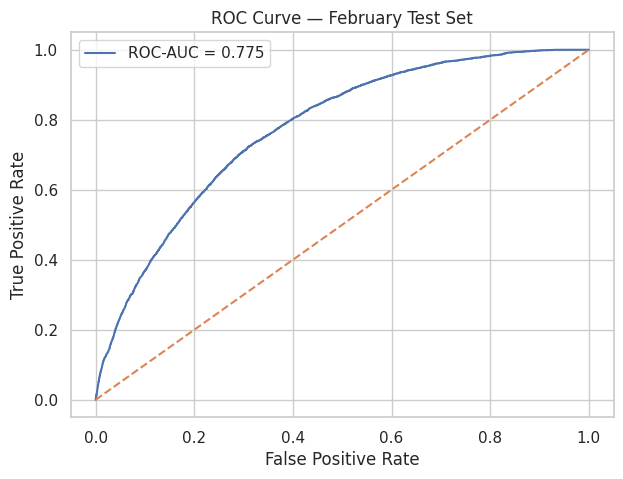

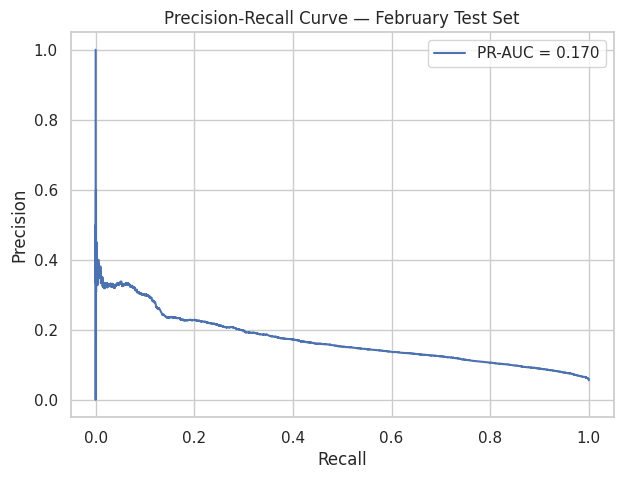

In [ ]:
# Cell 9 — Evaluate on the held-out February test set

p_test_raw = model.predict_proba(X_te)[:, 1]

p_test = calibrate(p_test_raw)

y_pred = (
    p_test_raw >= THRESHOLD
).astype(int)


metrics = {
    "accuracy": accuracy_score(
        y_te,
        y_pred
    ),

    "precision": precision_score(
        y_te,
        y_pred,
        zero_division=0
    ),

    "recall": recall_score(
        y_te,
        y_pred,
        zero_division=0
    ),

    "f1": f1_score(
        y_te,
        y_pred,
        zero_division=0
    ),

    "roc_auc": roc_auc_score(
        y_te,
        p_test
    ),

    "pr_auc": average_precision_score(
        y_te,
        p_test
    ),

    "brier": brier_score_loss(
        y_te,
        p_test
    )
}


print("Test-set performance:")
for name, value in metrics.items():
    print(f"{name:10s}: {value:.4f}")


# Confusion matrix

cm = confusion_matrix(
    y_te,
    y_pred
)

print("\nConfusion matrix:")
print(cm)


# ROC curve

fpr, tpr, _ = roc_curve(
    y_te,
    p_test
)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {metrics['roc_auc']:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — February Test Set")
plt.legend()
plt.show()


# Precision-Recall curve

precision, recall, _ = precision_recall_curve(
    y_te,
    p_test
)

plt.figure(figsize=(7, 5))
plt.plot(
    recall,
    precision,
    label=f"PR-AUC = {metrics['pr_auc']:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — February Test Set")
plt.legend()
plt.show()

In [ ]:
# Cell 10 — Personalized product recommender

class Recommender:

    def __init__(self, df, f, model, calibrator):
        self.df = df
        self.f = f
        self.model = model
        self.calibrator = calibrator

        # Product catalogue
        self.prod = (
            df[
                [
                    "product_id",
                    "category_id",
                    "category_code",
                    "brand",
                    "price",
                    "top_category"
                ]
            ]
            .drop_duplicates("product_id")
            .copy()
        )

        # User history
        self.u = (
            df[
                [
                    "user_id",
                    "event_time",
                    "product_id",
                    "category_id",
                    "top_category",
                    "is_view",
                    "is_cart",
                    "is_purchase"
                ]
            ]
            .copy()
        )

    def _candidate_products(
        self,
        categories=None,
        keyword=None,
        max_price=None,
        limit=500
    ):

        c = self.prod.copy()

        # Category filter
        if categories:
            c = c[
                c["top_category"].isin(categories)
            ]

        # Keyword filter
        if keyword:
            kw = keyword.lower()

            mask = (
                c["category_code"]
                .astype(str)
                .str.lower()
                .str.contains(
                    kw,
                    regex=False,
                    na=False
                )
                |
                c["brand"]
                .astype(str)
                .str.lower()
                .str.contains(
                    kw,
                    regex=False,
                    na=False
                )
            )

            c = c[mask]

        # Budget filter
        if max_price is not None:
            c = c[
                c["price"] <= max_price
            ]

        # Limit candidate pool
        if len(c) > limit:
            c = c.sample(
                limit,
                random_state=RANDOM_STATE
            )

        return c

    def _user_snapshot(self, user_id):

        if user_id is None:
            return None

        hist = self.u[
            self.u["user_id"] == user_id
        ]

        if hist.empty:
            return None

        return hist

    def recommend(
        self,
        user_id=None,
        categories=None,
        keyword=None,
        max_price=None,
        n=10
    ):

        candidates = self._candidate_products(
            categories=categories,
            keyword=keyword,
            max_price=max_price
        )

        if candidates.empty:
            print(
                "No products matched your filters."
            )
            return pd.DataFrame()

        # -------------------------------------------------
        # Create prediction rows for candidates
        # -------------------------------------------------

        now = df["event_time"].max()

        rows = []

        for _, p in candidates.iterrows():

            rows.append(
                {
                    "event_time": now,
                    "user_id": user_id,
                    "product_id": p["product_id"],
                    "category_id": p["category_id"],
                    "category_code": p["category_code"],
                    "brand": p["brand"],
                    "price": p["price"],
                    "top_category": p["top_category"],
                    "user_session": "RECOMMENDER"
                }
            )

        cand = pd.DataFrame(rows)


        # -------------------------------------------------
        # Build prior-history features
        # -------------------------------------------------

        feature_rows = []

        for _, row in cand.iterrows():

            product_id = row["product_id"]
            category_id = row["category_id"]
            brand = row["brand"]
            uid = row["user_id"]

            product_hist = self.f[
                self.f["product_id"]
                == product_id
            ]

            category_hist = self.f[
                self.f["category_id"]
                == category_id
            ]

            brand_hist = self.f[
                self.f["brand"]
                == brand
            ]

            if uid is None:

                user_hist = self.f.iloc[0:0]

                user_category_hist = (
                    self.f.iloc[0:0]
                )

                user_product_hist = (
                    self.f.iloc[0:0]
                )

            else:

                user_hist = self.f[
                    self.f["user_id"] == uid
                ]

                user_category_hist = (
                    self.f[
                        (self.f["user_id"] == uid)
                        &
                        (
                            self.f["category_id"]
                            == category_id
                        )
                    ]
                )

                user_product_hist = (
                    self.f[
                        (self.f["user_id"] == uid)
                        &
                        (
                            self.f["product_id"]
                            == product_id
                        )
                    ]
                )


            def count(hist, column):
                if hist.empty:
                    return 0
                return hist[column].sum()


            x = {
                "price": row["price"],
                "top_category": row["top_category"],
                "brand": row["brand"],

                "p_views": count(
                    product_hist,
                    "is_view"
                ),
                "p_carts": count(
                    product_hist,
                    "is_cart"
                ),
                "p_purchases": count(
                    product_hist,
                    "is_purchase"
                ),

                "c_views": count(
                    category_hist,
                    "is_view"
                ),
                "c_carts": count(
                    category_hist,
                    "is_cart"
                ),
                "c_purchases": count(
                    category_hist,
                    "is_purchase"
                ),

                "b_views": count(
                    brand_hist,
                    "is_view"
                ),
                "b_carts": count(
                    brand_hist,
                    "is_cart"
                ),
                "b_purchases": count(
                    brand_hist,
                    "is_purchase"
                ),

                "u_views": count(
                    user_hist,
                    "is_view"
                ),
                "u_carts": count(
                    user_hist,
                    "is_cart"
                ),
                "u_purchases": count(
                    user_hist,
                    "is_purchase"
                ),

                "u_sessions": (
                    user_hist["user_session"]
                    .nunique()
                    if not user_hist.empty
                    else 0
                ),

                "uc_views": count(
                    user_category_hist,
                    "is_view"
                ),
                "uc_carts": count(
                    user_category_hist,
                    "is_cart"
                ),
                "uc_purchases": count(
                    user_category_hist,
                    "is_purchase"
                ),

                "up_views": count(
                    user_product_hist,
                    "is_view"
                ),
                "up_carts": count(
                    user_product_hist,
                    "is_cart"
                ),
                "up_purchases": count(
                    user_product_hist,
                    "is_purchase"
                ),

                "c_price_sum": (
                    (
                        category_hist["price"]
                        * category_hist["is_view"]
                    ).sum()
                    if not category_hist.empty
                    else 0
                ),

                "u_price_sum": (
                    (
                        user_hist["price"]
                        * user_hist["is_view"]
                    ).sum()
                    if not user_hist.empty
                    else 0
                ),

                "u_events": (
                    len(user_hist)
                )
            }

            feature_rows.append(x)


        raw_features = pd.DataFrame(
            feature_rows
        )


        # -------------------------------------------------
        # Additional temporal fields
        # -------------------------------------------------

        if user_id is not None:

            hist = self.f[
                self.f["user_id"] == user_id
            ]

            if not hist.empty:

                first_time = (
                    hist["event_time"].min()
                )

                last_time = (
                    hist["event_time"].max()
                )

                raw_features[
                    "u_first_time"
                ] = first_time

                raw_features[
                    "u_last_time"
                ] = last_time

            else:

                raw_features[
                    "u_first_time"
                ] = pd.NaT

                raw_features[
                    "u_last_time"
                ] = pd.NaT

        else:

            raw_features[
                "u_first_time"
            ] = pd.NaT

            raw_features[
                "u_last_time"
            ] = pd.NaT


        # Required helper columns
        raw_features["c_views"] = raw_features["c_views"]
        raw_features["u_views"] = raw_features["u_views"]


        # -------------------------------------------------
        # Convert to model features
        # -------------------------------------------------

        X = finalize_features(
            raw_features,
            pd.Series(
                now,
                index=raw_features.index
            )
        )

        # Make sure columns are exactly the training columns
        X = X.reindex(
            columns=FEATURES
        )


        # -------------------------------------------------
        # Predict purchase probabilities
        # -------------------------------------------------

        probabilities = purchase_probability(
            X
        )


        result = candidates.copy()

        result[
            "purchase_probability"
        ] = probabilities


        # -------------------------------------------------
        # Rank recommendations
        # -------------------------------------------------

        result = (
            result
            .sort_values(
                "purchase_probability",
                ascending=False
            )
            .head(n)
            .reset_index(drop=True)
        )


        return result[
            [
                "product_id",
                "category_code",
                "brand",
                "price",
                "purchase_probability"
            ]
        ]


# Create recommender
rec = Recommender(
    df=df,
    f=f,
    model=model,
    calibrator=calibrator
)

print("Recommender ready!")

print(
    "Products available:",
    rec.prod["product_id"].nunique()
)

print(
    "Users available:",
    rec.u["user_id"].nunique()
)

Recommender ready!
Products available: 53452
Users available: 407237


In [ ]:
# Cell 11 — Interactive recommendation demo

def show(recs):

    if recs.empty:
        print(
            "No products in the dataset match these choices. "
            "Try another category or keyword."
        )
        return

    print("\n" + "=" * 70)
    print("PERSONALIZED RECOMMENDATIONS")
    print("=" * 70)

    for i, r in recs.iterrows():

        product_id = r["product_id"]
        category = r["category_code"]
        brand = r["brand"]
        price = r["price"]
        probability = r["purchase_probability"]

        if category == "unknown":
            category = (
                f"category_id "
                f"{rec.prod.loc[product_id, 'category_id']}"
            )

        if brand == "unknown":
            brand = "brand not recorded"

        your_views = r.get("your_views", 0)
        your_category_views = r.get(
            "your_category_views", 0
        )

        print(
            f"\n{i + 1}. Product ID : {product_id}"
        )

        print(
            f"   Category    : {category}"
        )

        print(
            f"   Brand       : {brand}"
        )

        print(
            f"   Price       : {price:.2f}"
        )

        print(
            f"   Purchase probability : "
            f"{probability:.1%}"
        )

        if your_views > 0:
            print(
                f"   You viewed this product "
                f"{int(your_views)} time(s)"
            )

        if your_category_views > 0:
            print(
                f"   You viewed this category "
                f"{int(your_category_views)} time(s)"
            )

    print("\n" + "=" * 70)


def run_demo():

    print(
        "\n"
        + "=" * 60
        + "\n"
        + "       CUSTOMER PURCHASE & RECOMMENDATION SYSTEM"
        + "\n"
        + "=" * 60
    )

    print("\nWelcome!\n")

    # Existing customer or new visitor
    uid = input(
        "Existing customer? Enter a user_id "
        "(or press Enter for new visitor): "
    ).strip()

    if uid.isdigit():

        user_id = int(uid)

        if user_id not in rec.u.index:
            print(
                "\nUser ID not found."
                "\nContinuing as a new visitor."
            )
            user_id = None

    else:
        user_id = None


    # Category menu
    menu = [
        c
        for c in rec.prod["top_category"]
        .value_counts()
        .index
        if c != "unknown"
    ]

    menu.append("unknown")

    print(
        "\nSelect your interests/categories."
    )

    print(
        "Enter numbers separated by commas."
    )

    print(
        "Press Enter for any category.\n"
    )

    for i, category in enumerate(menu, 1):
        print(
            f"[{i:2d}] {category}"
        )


    category_input = input(
        "\nYour choice: "
    ).strip()

    picks = []

    if category_input:

        for value in category_input.replace(
            " ", ""
        ).split(","):

            if value.isdigit():

                number = int(value)

                if 1 <= number <= len(menu):

                    picks.append(
                        menu[number - 1]
                    )


    # Keyword
    print(
        "\nWhat are you looking for?"
    )

    print(
        "Examples: samsung, videocards, "
        "telephone, headphones"
    )

    keyword = input(
        "Keyword: "
    ).strip()

    if keyword == "":
        keyword = None


    # Budget
    budget = input(
        "\nMaximum price "
        "(press Enter for no limit): "
    ).strip()

    if budget:

        try:
            max_price = float(budget)

        except ValueError:

            print(
                "Invalid price. "
                "Using no price limit."
            )

            max_price = None

    else:
        max_price = None


    # Generate recommendations
    print(
        "\nGenerating personalized recommendations..."
    )

    recommendations = rec.recommend(
        user_id=user_id,
        categories=picks if picks else None,
        keyword=keyword,
        max_price=max_price,
        n=10
    )

    show(recommendations)


# Run the demo
run_demo()


       CUSTOMER PURCHASE & RECOMMENDATION SYSTEM

Welcome!

Existing customer? Enter a user_id (or press Enter for new visitor): 

Select your interests/categories.
Enter numbers separated by commas.
Press Enter for any category.

[ 1] electronics
[ 2] computers
[ 3] stationery
[ 4] appliances
[ 5] construction
[ 6] auto
[ 7] accessories
[ 8] country_yard
[ 9] furniture
[10] jewelry
[11] kids
[12] medicine
[13] apparel
[14] sport
[15] unknown

Your choice: 4

What are you looking for?
Examples: samsung, videocards, telephone, headphones
Keyword: samsung

Maximum price (press Enter for no limit): 100

Generating personalized recommendations...

PERSONALIZED RECOMMENDATIONS

1. Product ID : 1558810
   Category    : appliances.environment.vacuum
   Brand       : samsung
   Price       : 62.24
   Purchase probability : 1.7%

2. Product ID : 171624
   Category    : appliances.environment.vacuum
   Brand       : samsung
   Price       : 62.78
   Purchase probability : 1.5%

3. Product ID : 